# Car Matchmaker: step by step

**Goal:** recommend used cars that fit a buyer's life, explain each pick, judge whether an advert is a good price, and
link to cars for sale near them.

**Data:** Kaggle *100,000 UK Used Car Data set*, real UK adverts scraped in 2020 across 9 brands.

**Contents**
1. Setup and cleaning
2. The market: prices, brands, fuels, gearboxes
3. What drives price: age, mileage, engine, fuel
4. Running costs: mpg and road tax
5. Fair-price model vs baselines (held-out test set)
6. Where the model is weaker
7. Is the fair range honest? (calibration)
8. What the model learned (permutation importance)
9. Depreciation and cost of ownership
10. From a sentence to requirements
11. Recommendations for four buyers, with reasons and links
12. Limits and next steps

## 1. Setup and cleaning

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from carmatch.data import load
from carmatch.catalogue import CATALOGUE, AMBIGUOUS
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b7b0"
df, log = load()
log

{'raw_rows': 99187, 'duplicates_removed': 1475, 'implausible_removed': 53, 'too_rare_removed': 12, 'rows': 97647, 'models': 194}

In [2]:
df.head()

,brand,model,year,price,transmission,mileage,fuel,tax,mpg,engine_size,age,model_key
0,Audi,A1,2017,12500,Manual,15735,Petrol,150,55.40,1.40,3,Audi A1
1,Audi,A6,2016,16500,Automatic,36203,Diesel,20,64.20,2.00,4,Audi A6
2,Audi,A1,2016,11000,Manual,29946,Petrol,30,55.40,1.40,4,Audi A1
3,Audi,A4,2017,16800,Automatic,25952,Diesel,145,67.30,2.00,3,Audi A4
4,Audi,A3,2019,17300,Manual,1998,Petrol,145,49.60,1.00,1,Audi A3


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"97,647.00","2,017.07",2.11,"1,996.00","2,016.00","2,017.00","2,019.00","2,020.00"
price,"97,647.00","16,773.44","9,870.87",590.00,"9,999.00","14,457.00","20,750.00","159,999.00"
mileage,"97,647.00","23,212.25","21,050.55",1.00,"7,670.00","17,677.00","32,492.00","323,000.00"
tax,"97,647.00",120.18,63.33,0.00,125.00,145.00,145.00,580.00
mpg,"97,647.00",55.02,13.58,0.30,47.10,54.30,62.80,235.40
engine_size,"97,416.00",1.67,0.55,1.00,1.20,1.60,2.00,6.60
age,"97,647.00",2.93,2.11,0.00,1.00,3.00,4.00,24.00


Cleaning removed 1,475 exact duplicate adverts, 53 impossible rows (a registration year of 2060, £0 prices, mpg up
to 470) and 12 rows too rare to model (3 "Electric", 9 "Other" gearboxes). That leaves 97,647 adverts for 194 models.
The data has effectively **no electric cars**, so the app says so rather than recommending one.

In [4]:
cover = df.model_key.isin(CATALOGUE).mean()
print(f"body/seats/size known for {cover:.2%} of adverts; {len(AMBIGUOUS)} mixed-up labels excluded from recommendations:")
for k, v in AMBIGUOUS.items(): print(" -", k, ":", v)

body/seats/size known for 99.35% of adverts; 2 mixed-up labels excluded from recommendations:
 - Mercedes-Benz CL Class : mostly CLA saloons (1.3-2.2L, up to 2020) though the CL coupe ended in 2014
 - Mercedes-Benz GL Class : mix of 7-seat GL (3.0L) and small GLA (1.6-2.1L) adverts

## 2. The market

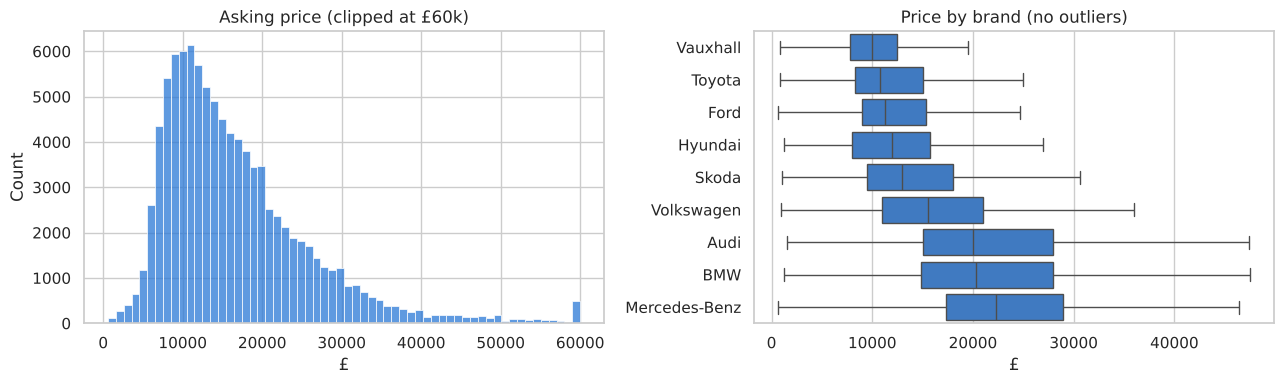

,adverts,median_price,median_age,median_miles
brand,,,,
Ford,17807,"11,289.00",3.00,"18,274.00"
Volkswagen,14893,"15,494.00",3.00,"16,558.00"
Vauxhall,13250,"9,998.00",3.00,"19,000.00"
Mercedes-Benz,12857,"22,299.00",2.00,"15,447.00"
BMW,10621,"20,320.00",3.00,"18,673.00"
Audi,10565,"20,000.00",3.00,"19,268.00"
Toyota,6698,"10,796.50",3.00,"18,571.50"
Skoda,6187,"12,998.00",2.00,"14,666.00"
Hyundai,4769,"11,990.00",3.00,"17,630.00"


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.price.clip(upper=60000), bins=60, color=BLUE, ax=axes[0]); axes[0].set(title="Asking price (clipped at £60k)", xlabel="£")
order = df.groupby("brand").price.median().sort_values().index
sns.boxplot(data=df, y="brand", x="price", order=order, showfliers=False, color=BLUE, ax=axes[1]); axes[1].set(title="Price by brand (no outliers)", xlabel="£", ylabel="")
plt.tight_layout(); plt.show()
df.groupby("brand").agg(adverts=("price", "size"), median_price=("price", "median"), median_age=("age", "median"), median_miles=("mileage", "median")).sort_values("adverts", ascending=False)

In [6]:
pd.concat({"fuel": df.fuel.value_counts(normalize=True), "gearbox": df.transmission.value_counts(normalize=True)}).mul(100).round(1).to_frame("% of adverts")

% of adverts
fuel    Petrol            55.30
        Diesel            41.40
        Hybrid             3.10
        Other              0.20
gearbox Manual            56.80
        Semi-Auto         22.80
        Automatic         20.30

In [7]:
df.model_key.value_counts().head(15).to_frame("adverts")

,adverts
model_key,
Ford Fiesta,6508
Volkswagen Golf,4797
Ford Focus,4554
Mercedes-Benz C Class,3694
Vauxhall Corsa,3284
Volkswagen Polo,3244
Vauxhall Astra,2654
Mercedes-Benz A Class,2474
BMW 3 Series,2434


Prices are right-skewed (a long tail of premium cars), which is why the model works on log(price) and why MAPE, a
percentage error, is the headline metric. Ford, Volkswagen and Vauxhall dominate the volume; the premium brands
(Mercedes-Benz, BMW, Audi) have the highest medians. Petrol and diesel make up almost all adverts; hybrids are about 3%.

## 3. What drives price

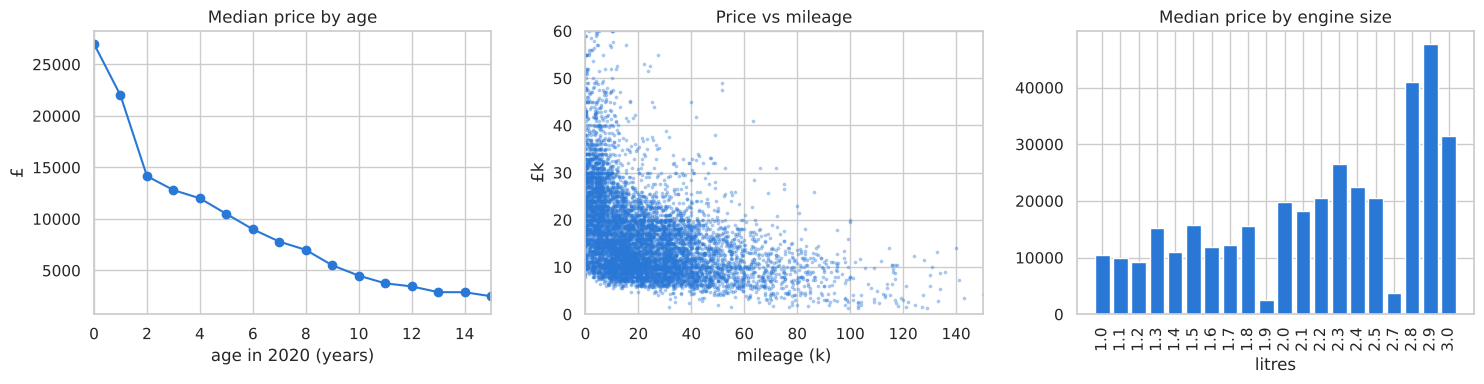

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
a = df.groupby("age").price.median()
axes[0].plot(a.index, a.values, marker="o", color=BLUE); axes[0].set(title="Median price by age", xlabel="age in 2020 (years)", ylabel="£", xlim=(0, 15))
s = df.sample(8000, random_state=0)
axes[1].scatter(s.mileage / 1000, s.price / 1000, s=3, alpha=0.3, color=BLUE); axes[1].set(title="Price vs mileage", xlabel="mileage (k)", ylabel="£k", xlim=(0, 150), ylim=(0, 60))
e = df.groupby(df.engine_size.round(1)).price.median().loc[0.9:3.1]
axes[2].bar(e.index.astype(str), e.values, color=BLUE); axes[2].set(title="Median price by engine size", xlabel="litres"); axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

In [9]:
# the same model, different spec: Focus by fuel and gearbox, 3-year-olds only
f = df[(df.model_key == "Ford Focus") & (df.age == 3)]
f.groupby(["fuel", "transmission"]).price.agg(["size", "median"])

size    median
fuel   transmission                
Diesel Automatic       11 12,300.00
       Manual         402 11,498.00
       Semi-Auto       22 12,194.00
Petrol Automatic       55 12,390.00
       Manual         600 11,499.00
       Semi-Auto       58 11,970.00

Age is the strongest single driver: the median price falls steeply over the first few years and keeps falling.
Mileage pushes in the same direction, and bigger engines cost more. Even within one model and age, an automatic Focus costs 7–8% more
than a manual, which is why a simple "median price for this model" baseline is weak.

## 4. Running costs: mpg and road tax

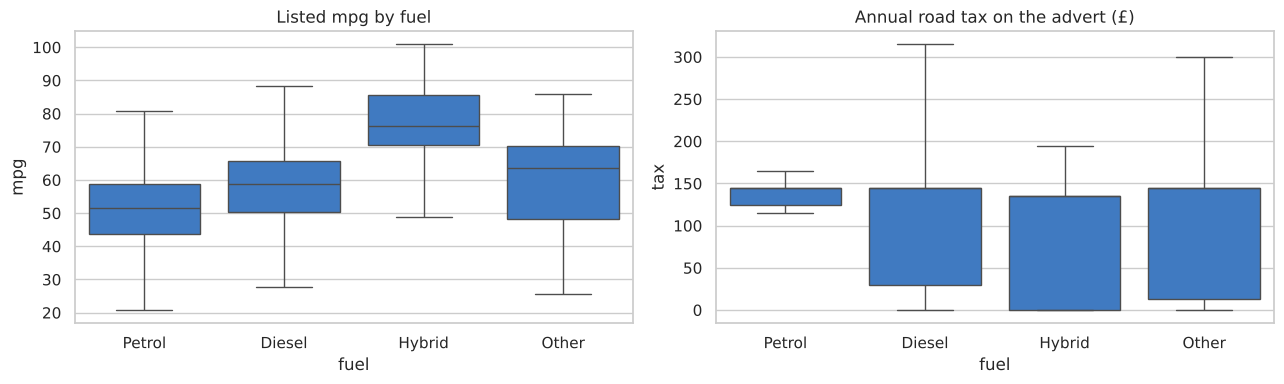

,mpg,tax
fuel,,
Diesel,58.90,145.00
Hybrid,76.40,135.00
Other,63.50,145.00
Petrol,51.40,145.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="fuel", y="mpg", showfliers=False, color=BLUE, ax=axes[0]); axes[0].set(title="Listed mpg by fuel")
sns.boxplot(data=df, x="fuel", y="tax", showfliers=False, color=BLUE, ax=axes[1]); axes[1].set(title="Annual road tax on the advert (£)")
plt.tight_layout(); plt.show()
df.groupby("fuel")[["mpg", "tax"]].median()

In [11]:
from carmatch.costs import Costs, annual_fuel_cost
c = Costs.load()
print("fuel price assumptions (£/litre):", c.fuel_price_per_litre)
for mpg, fuel in [(40, "Petrol"), (55, "Petrol"), (65, "Diesel"), (75, "Hybrid")]:
    print(f"{mpg} mpg {fuel:6s}: £{annual_fuel_cost([mpg], [fuel], 10000, c)[0]:,.0f} a year at 10,000 miles")

fuel price assumptions (£/litre): {'Petrol': 1.35, 'Diesel': 1.42, 'Hybrid': 1.35, 'Other': 1.35}
40 mpg Petrol: £1,534 a year at 10,000 miles
55 mpg Petrol: £1,116 a year at 10,000 miles
65 mpg Diesel: £993 a year at 10,000 miles
75 mpg Hybrid: £818 a year at 10,000 miles

Hybrids list the highest mpg, then diesels, then petrol. Listed mpg is the official figure, so real-world costs are
usually higher: the app has a slider to scale it down, and the fuel prices are editable assumptions, not live data.

## 5. Fair-price model vs baselines

Frozen split: 70% train, 10% calibration (only used for the fair range), 20% test, scored once.
Baselines are what a buyer could do by hand: the median price of that model, and of that model and year.

In [12]:
from carmatch.price_model import evaluate, NAMES
model, out, t = evaluate(df)
res = pd.DataFrame(out["overall"]).T.rename(index=NAMES)
res[["mae", "mape", "median_ape", "within_10pct", "r2"]]

,mae,mape,median_ape,within_10pct,r2
Gradient boosting (all features),"1,086.15",6.70,5.16,78.61,0.97
Median for model,"4,022.34",28.37,17.81,30.20,0.60
Median for model + year,"2,126.45",13.38,9.10,53.63,0.83


In [13]:
o = out["overall"]
print(f"MAPE {o['gbm']['mape']:.1f}% vs {o['model_year_median']['mape']:.1f}% for the model+year median: "
      f"{1 - o['gbm']['mape'] / o['model_year_median']['mape']:.0%} lower error; MAE £{o['gbm']['mae']:,.0f} vs £{o['model_year_median']['mae']:,.0f}")

MAPE 6.7% vs 13.4% for the model+year median: 50% lower error; MAE £1,086 vs £2,126

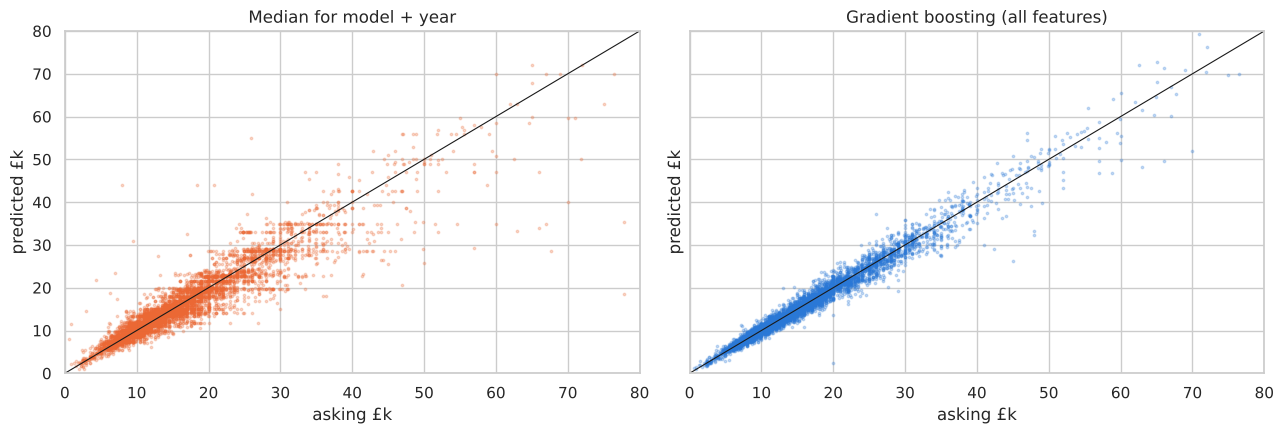

In [14]:
s = t.sample(6000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, k, col in [(axes[0], "model_year_median", ORANGE), (axes[1], "gbm", BLUE)]:
    ax.scatter(s.price / 1e3, s[f"pred_{k}"] / 1e3, s=3, alpha=0.25, color=col); ax.plot([0, 80], [0, 80], color="k", lw=0.8)
    ax.set(xlim=(0, 80), ylim=(0, 80), title=NAMES[k], xlabel="asking £k", ylabel="predicted £k")
plt.tight_layout(); plt.show()

Gradient boosting halves the error of the best hand method and gets about four in five adverts within 10% of their
asking price. The baseline's horizontal stripes show its weakness: every car of the same model and year gets the same
price, whatever its mileage, engine or gearbox.

## 6. Where the model is weaker

In [15]:
pd.DataFrame(out["by_price_band"]).T

,n,gbm,model_median,model_year_median
<£7.5k,"1,936.00",9.95,83.76,27.73
£7.5–12.5k,"6,073.00",6.48,24.29,11.56
£12.5–20k,"6,442.00",6.17,20.02,11.34
£20–35k,"4,223.00",6.21,21.76,11.87
£35k+,856.00,7.24,27.60,16.66


In [16]:
pd.DataFrame(out["by_brand"]).T.sort_values("gbm")

,gbm,model_median,model_year_median
Toyota,6.03,26.36,16.46
Hyundai,6.21,20.58,11.28
Volkswagen,6.32,28.65,14.16
Mercedes-Benz,6.58,31.96,15.18
BMW,6.79,35.69,15.75
Ford,6.82,28.09,11.53
Vauxhall,7.01,23.06,10.89
Audi,7.06,32.17,13.17
Skoda,7.18,21.08,12.91


In [17]:
t["ape"] = (t.pred_gbm - t.price).abs() / t.price * 100
t.groupby(pd.cut(t.year, [1995, 2010, 2014, 2017, 2020]), observed=True).ape.agg(["size", "mean", "median"])

,size,mean,median
year,,,
"(1995, 2010]",257,25.14,14.80
"(2010, 2014]",1593,8.31,6.49
"(2014, 2017]",8963,6.18,4.95
"(2017, 2020]",8717,6.39,5.06


In [18]:
worst = t.sort_values("ape", ascending=False).head(8)
worst[["model_key", "year", "mileage", "fuel", "transmission", "price", "pred_gbm", "ape"]]

,model_key,year,mileage,fuel,transmission,price,pred_gbm,ape
37937,Ford Mondeo,2008,1,Diesel,Manual,1299,"5,223.53",302.12
54883,Mercedes-Benz M Class,2004,165000,Petrol,Semi-Auto,1995,"6,441.45",222.88
55320,Mercedes-Benz A Class,2003,109090,Petrol,Manual,650,"1,950.32",200.05
16885,BMW 1 Series,2020,10,Petrol,Semi-Auto,11995,"34,144.33",184.65
38466,Ford Focus,2005,71214,Petrol,Manual,795,"2,188.75",175.31
88956,Volkswagen Passat,2010,168000,Diesel,Manual,1495,"3,830.71",156.23
55515,Mercedes-Benz S Class,1999,34000,Petrol,Automatic,5995,"13,968.42",133.00
69198,Toyota Avensis,2007,120000,Petrol,Automatic,1200,"2,658.45",121.54


Error is highest for the cheapest cars (under £7,500) and for old cars, where condition, history and trim, which
the data doesn't contain, matter more than age and mileage. The biggest misses look like adverts whose asking price is
unusual for the spec (rare trims, possible typos), which is exactly what a buyer would want flagged.

## 7. Is the fair range honest?

In [19]:
fr = model.fair_range(t)
inside = (t.price >= fr.low) & (t.price <= fr.high)
print(f"target 80%; test coverage {inside.mean():.1%}; range is ±{(np.exp(model.q80) - 1):.1%} around the fair price")
t.assign(inside=inside).groupby("brand").inside.mean().mul(100).round(1).to_frame("% of test adverts inside the range")

target 80%; test coverage 80.0%; range is ±10.9% around the fair price

,% of test adverts inside the range
brand,
Audi,76.70
BMW,79.40
Ford,79.50
Hyundai,82.50
Mercedes-Benz,80.90
Skoda,76.00
Toyota,84.10
Vauxhall,79.50
Volkswagen,81.70


The range is built by split-conformal prediction on the calibration set, and on the untouched test set it covers
80% of adverts, as intended. Coverage varies by brand, so a "Great price" verdict is a prompt to look closer, not proof.

## 8. What the model learned

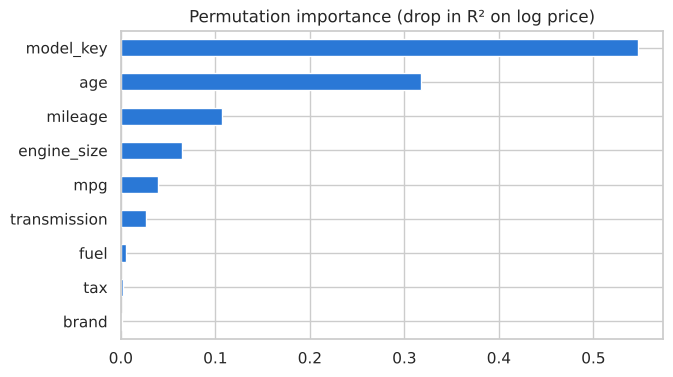

,0
model_key,0.55
age,0.32
mileage,0.11
engine_size,0.06
mpg,0.04
transmission,0.03
fuel,0.01
tax,0.00
brand,0.00


In [20]:
from sklearn.inspection import permutation_importance
from carmatch.price_model import _frame, FEATURES
samp = t.sample(3000, random_state=1)
pi = permutation_importance(model.gbm, _frame(samp, model.cats), np.log(samp.price), n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(color=BLUE, figsize=(7, 4), title="Permutation importance (drop in R² on log price)"); plt.show()
imp.sort_values(ascending=False)

The model leans most on which car it is and how old it is, then mileage; engine size, mpg and gearbox refine it.
Brand adds almost nothing once the model is known, and tax is largely implied by age and mpg.

## 9. Depreciation and cost of ownership

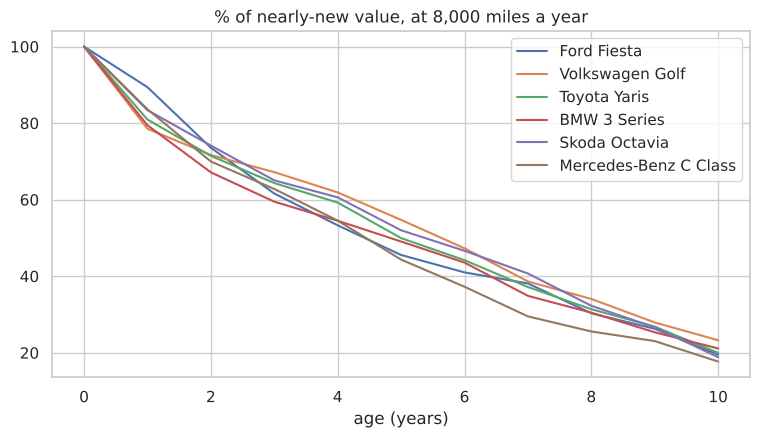

,3,6
Ford Fiesta,61.60,41.00
Volkswagen Golf,67.20,47.30
Toyota Yaris,64.30,44.20
BMW 3 Series,59.50,43.60
Skoda Octavia,65.00,46.60
Mercedes-Benz C Class,62.80,37.20


In [21]:
from carmatch.price_model import PriceModel
pm = PriceModel.load()
rows = []
for mk in ["Ford Fiesta", "Volkswagen Golf", "Toyota Yaris", "BMW 3 Series", "Skoda Octavia", "Mercedes-Benz C Class"]:
    sub = df[df.model_key == mk]; typ = sub.mode().iloc[0]
    f = pd.DataFrame([{**typ.to_dict(), "age": a, "mileage": max(500, a * 8000), "engine_size": sub.engine_size.median(), "mpg": sub.mpg.median()} for a in range(11)])
    p = pm.predict(f); rows.append(pd.Series(p / p[0] * 100, name=mk))
dep = pd.DataFrame(rows).T
dep.plot(figsize=(9, 4.5), title="% of nearly-new value, at 8,000 miles a year", xlabel="age (years)"); plt.show()
dep.loc[[3, 6]].T.round(1)

In [22]:
from carmatch.costs import ownership
ex = df[(df.model_key.isin(["Ford Focus", "Toyota Yaris", "BMW 3 Series"])) & (df.age == 3)].groupby("model_key").head(200)
own = ownership(ex, pm, years=3, miles=10000, c=c)
pd.concat([ex[["model_key", "fuel"]], own], axis=1).groupby(["model_key", "fuel"])[["price_now", "fuel_year", "tax_year", "depreciation", "cost_per_year"]].median().round(0)

price_now  fuel_year  ...  depreciation  cost_per_year
model_key    fuel                          ...                             
BMW 3 Series Diesel  18,741.00   1,028.00  ...      5,552.00       3,103.00
             Hybrid  19,500.00     456.00  ...      5,764.00       2,494.00
             Other   17,000.00     456.00  ...      4,217.00       1,862.00
             Petrol  15,460.00   1,260.00  ...      4,013.00       2,669.00
Ford Focus   Diesel  11,998.00     869.00  ...      4,675.00       2,503.00
             Petrol  11,591.00   1,021.00  ...      4,569.00       2,702.00
Toyota Yaris Diesel   8,495.00     800.00  ...      2,722.00       1,707.00
             Hybrid  12,498.00     787.00  ...      3,031.00       1,860.00
             Petrol   9,498.00   1,058.00  ...      3,196.00       2,217.00

[9 rows x 5 columns]

Depreciation is usually the biggest cost of owning a nearly-new car, bigger than fuel and tax combined, which is why
the recommender ranks on cost per year of ownership (depreciation + fuel + tax) and not just the sticker price.

## 10. From a sentence to requirements

In [23]:
from carmatch.needs import parse_lifestyle
for text in ["Family of five in London with a dog, 40 mile commute, about £12k",
             "Just passed my test, first car, cheap to run, under £5k, LS6 2AB",
             "Three kids, we tow a small caravan, rural Wales, automatic, budget £20,000",
             "first car but I have a big dog"]:
    n, why = parse_lifestyle(text)
    print(text); [print("   •", w) for w in why]; print()

Family of five in London with a dog, 40 mile commute, about £12k
   • Budget up to £12,000
   • At least 5 seats
   • Space matters with a full car
   • Dog: medium or bigger, with a boot it can ride in
   • About 11,700 miles a year
   • Clean-air-zone compliant (ULEZ standard: petrol 2006 on, diesel late 2015 on), for London

Just passed my test, first car, cheap to run, under £5k, LS6 2AB
   • Budget up to £5,000
   • New driver: small engine (1.4L or less) to keep insurance down
   • Running costs matter most
   • Near LS6 2AB

Three kids, we tow a small caravan, rural Wales, automatic, budget £20,000
   • Budget up to £20,000
   • At least 5 seats
   • Space matters with a full car
   • Rural roads: SUV or estate preferred (check for four-wheel drive on the advert)
   • Towing: 1.8L or bigger engine, SUV/estate/pickup (check towing limit on the advert)
   • Automatic gearbox

first car but I have a big dog
   • Dog: medium or bigger, with a boot it can ride in
   • Note: conflicti

Each requirement comes with the reason it was set, and clashing needs (a new driver's small car vs a big dog) are
reported instead of silently resolved. The optional LLM reader returns the same fields, validated against the same lists.

## 11. Recommendations for four buyers

In [24]:
from carmatch.recommend import recommend, relax_suggestions, why_empty
def show(text):
    n, why = parse_lifestyle(text)
    picks, info = recommend(df, n, pm, c)
    print(f"■ {text}\n  {info['matching_listings']:,} adverts, {info['models_considered']} models fit")
    if not picks: print("  ", why_empty(info, relax_suggestions(df, n, c)))
    for i, p in enumerate(picks, 1):
        s = p.stats
        print(f"  {i}. {p.model_key} ({p.fuel.lower()}): ~£{s['price']:,.0f}, £{s['cost_year']:,.0f}/yr to own, match {p.score:.0%}")
        print("     +", " | ".join(p.reasons))
        if p.tradeoffs: print("     −", " | ".join(p.tradeoffs))
    return picks
picks = show("Family of five in London with a dog, 40 mile commute, about £12k, SE15 4QF")

■ Family of five in London with a dog, 40 mile commute, about £12k, SE15 4QF
  8,133 adverts, 27 models fit
  1. Volkswagen Golf SV (diesel): ~£9,894, £1,970/yr to own, match 74%
     + About £1,043 a year on fuel and tax at 11,700 miles (72 mpg listed) | 5 seats, medium MPV | Expected to lose about 28% of its value over 3 years
  2. Toyota Verso (diesel): ~£11,498, £2,628/yr to own, match 74%
     + 78% of matching adverts are priced under the model's fair value | 7 seats, medium MPV | About £1,233 a year on fuel and tax at 11,700 miles (63 mpg listed)
  3. Ford Grand C-MAX (diesel): ~£10,496, £2,283/yr to own, match 71%
     + 7 seats, medium MPV | About £1,206 a year on fuel and tax at 11,700 miles (64 mpg listed) | Expected to lose about 30% of its value over 3 years
  4. Ford Kuga (diesel): ~£11,300, £2,320/yr to own, match 71%
     + 83% of matching adverts are priced under the model's fair value | Expected to lose about 26% of its value over 3 years | 2.0-litre engine (typical f

In [25]:
_ = show("Just passed my test, first car, cheap to run, under £5k, LS6 2AB")

■ Just passed my test, first car, cheap to run, under £5k, LS6 2AB
  1,073 adverts, 18 models fit
  1. Vauxhall Viva (petrol): ~£4,990, £1,026/yr to own, match 77%
     + About £802 a year on fuel and tax at 8,000 miles (63 mpg listed) | 90% of matching adverts are priced under the model's fair value | Typically 4 years old with 37,653 miles
  2. Toyota Aygo (petrol): ~£4,350, £1,140/yr to own, match 77%
     + About £747 a year on fuel and tax at 8,000 miles (66 mpg listed) | 59% of matching adverts are priced under the model's fair value | Typically 7 years old with 44,000 miles
     − Smaller than the alternatives (city hatchback)
  3. Skoda Citigo (petrol): ~£4,698, £1,161/yr to own, match 72%
     + About £802 a year on fuel and tax at 8,000 miles (63 mpg listed) | 62% of matching adverts are priced under the model's fair value | Typically 6 years old with 46,900 miles
  4. Volkswagen Up (petrol): ~£4,698, £1,137/yr to own, match 70%
     + About £802 a year on fuel and tax at 8,0

In [26]:
_ = show("Three kids, we tow a small caravan, rural Wales, automatic, budget £20,000")

■ Three kids, we tow a small caravan, rural Wales, automatic, budget £20,000
  2,185 adverts, 25 models fit
  1. Toyota RAV4 (hybrid): ~£18,998, £2,906/yr to own, match 81%
     + 2.5-litre engine (typical for the adverts that fit) | About £872 a year on fuel and tax at 8,000 miles (58 mpg listed) | 55% of matching adverts are priced under the model's fair value
  2. Toyota C-HR (hybrid): ~£18,995, £2,195/yr to own, match 69%
     + About £796 a year on fuel and tax at 8,000 miles (74 mpg listed) | 57% of matching adverts are priced under the model's fair value | Typically 3 years old with 27,893 miles
     − Modest engine (1.8L) | Smaller than the alternatives (medium SUV)
  3. Mercedes-Benz GLC Class (diesel): ~£19,490, £3,352/yr to own, match 69%
     + 62% of matching adverts are priced under the model's fair value | About £1,039 a year on fuel and tax at 8,000 miles (56 mpg listed) | 2.1-litre engine (typical for the adverts that fit)
  4. Mercedes-Benz GLA Class (diesel): ~£17,49

In [27]:
_ = show("retired, short trips, bad back, want a hybrid, £10k")

■ retired, short trips, bad back, want a hybrid, £10k
  0 adverts, 0 models fit
   No adverts in the data meet every requirement. Options: drop the fuel requirement (53 models); drop the body requirement (3 models).

In [28]:
# dealer links for the first family pick: today's stock near the postcode, already filtered
for l in picks[0].links: print(f"{l['site']:12s} {l['url']}")

AutoTrader   https://www.autotrader.co.uk/car-search?make=Volkswagen&model=Golf+SV&postcode=SE154QF&radius=50&price-to=12000&year-from=2016&fuel-type=Diesel
eBay Motors  https://www.ebay.co.uk/sch/i.html?_nkw=Volkswagen+Golf+SV&_sacat=9801&_udhi=12000&_stpos=SE154QF&_sadis=50&_sop=15
Gumtree      https://www.gumtree.com/search?search_category=cars&q=Volkswagen+Golf+SV&search_location=SE154QF&max_price=12000&distance=50

In [29]:
picks[0].examples.round(2)

,year,age,mileage,transmission,engine_size,mpg,price_now,fair,deal_ratio,cost_per_year
97183,2016,4,50777,Manual,1.60,72.40,"7,999.00","8,795.70",0.91,"1,621.37"
97103,2016,4,57950,Manual,1.60,72.40,"7,797.00","8,591.15",0.91,"1,654.63"
97212,2017,3,71600,Manual,1.60,72.40,"7,995.00","7,944.22",1.01,"1,737.47"
97086,2016,4,68508,Manual,2.00,65.70,"7,940.00","8,296.62",0.96,"1,776.51"
97200,2018,2,23689,Automatic,1.60,70.60,"11,880.00","13,154.57",0.90,"1,815.60"


The London family gets roomy diesel MPVs (two with seven seats) and SUVs that meet ULEZ (diesels from 2016 on), each
with the reasons it ranked. When nothing fits, the app says which requirement to loosen and how many models that would open up.
The links search AutoTrader, eBay and Gumtree for that model, budget, fuel and the buyer's postcode, so the buyer sees
real cars for sale today at dealers near them.

## 12. Limits and next steps

* **2020 prices.** The adverts are from 2020; the app's price-level slider rescales them, and the deal verdict uses the
  ratio to fair value, which travels better than pounds. Next: retrain on fresh adverts (for example via the eBay API).
* **No EVs, no condition data.** Electric cars are absent; trim, condition and service history aren't in the data. The
  number-plate check (DVLA + MOT history) covers part of the gap: mileage at every test, failures, advisories, clocking.
* **Body, seats and size** come from a hand-built catalogue of the main version of each model: check the advert.
* **Random split.** The same car could appear twice under different adverts; exact duplicates are removed, near
  duplicates may remain, so the test score may be slightly optimistic.
* **Fair use of links.** No scraping: the app only builds the same search URLs a buyer would type, and uses official APIs
  (eBay, DVLA, DVSA) with the user's own keys.